# QE019: Lopsided Noise

**When a qubit's errors are almost all of one kind, you can build error correction that is much cheaper.**

A qubit can go wrong in two basic ways. A **bit flip** (X error) swaps $|0\rangle$ and $|1\rangle$. A **phase flip**
(Z error) leaves them in place but flips the sign between them, which ruins any superposition. Standard quantum error
correction, such as the square surface code, assumes both are equally likely and pays equally to protect against each.

Some hardware is far from that. A **cat qubit** stores information in two coherent states of light in a microwave
resonator, $|{+\alpha}\rangle$ and $|{-\alpha}\rangle$, kept in place by a drive that pumps photons in pairs. Bit flips
would need the field to jump from one to the other, and they become **exponentially rare** as the field gets bigger.
Phase flips, caused by losing a single photon, only grow **linearly**. The noise becomes extremely **biased**, and the
error-correcting code can be designed around that.

This exercise follows that idea from the physics of one oscillator up to the layout of a code:

* **Part A (one exact answer, Euler-style):** a surface code stretched in one direction, with its failure probability
  computed exactly by enumerating every error pattern.
* **Part B1:** how the stretched code wins over the square one, and where it stops winning.
* **Part B2:** where the bias comes from: the cat qubit's error rates computed from its master equation.
* **Part B3:** gates that keep the bias: why ordinary qubits cannot do a bias-preserving CNOT and cat qubits can.
* **Part B4:** the cat-qubit repetition code: trading photon number against code length.
* **Part B5:** high-rate codes: many logical qubits in one block, with one long distance and one short one.
* **Animation:** Wigner-function movies of a cat qubit: phase information fades, bit information stays.

### Words used in this notebook

| term | meaning |
|---|---|
| **bit flip (X) / phase flip (Z)** | the two basic qubit errors; a Y error is both at once |
| **bias η** | how much more likely phase flips are than bit flips, $\eta = p_Z / p_X$ |
| **coherent state $\lvert\alpha\rangle$** | the most classical state of light: a wave with amplitude $\alpha$ and on average $\bar n = \lvert\alpha\rvert^2$ photons |
| **cat state** | a superposition of two opposite coherent states, $\lvert{+\alpha}\rangle \pm \lvert{-\alpha}\rangle$ |
| **two-photon dissipation** | the engineered process that removes photons in pairs and holds the oscillator on the two states $\pm\alpha$ |
| **master equation / Lindblad** | the equation for how an open quantum system (one that loses energy to its surroundings) evolves |
| **Wigner function** | a picture of a quantum state in phase space; negative regions (fringes) signal quantum superposition |
| **parity** | whether the photon number is even or odd; it tells the two cat states apart |
| **stabiliser / check** | a multi-qubit measurement that reveals errors without disturbing the stored information |
| **syndrome** | the pattern of check outcomes |
| **logical error** | an error the code cannot undo, which damages the stored information |
| **distance $d_X$, $d_Z$** | the fewest bit flips (phase flips) that cause a logical error, undetected |
| **surface code** | the leading code: qubits on a grid, checks on the squares between them |
| **maximum-likelihood (ML) decoding** | choosing the most probable correction given the syndrome; the best possible decoder |
| **repetition code** | one bit copied $d$ times and read by majority vote; protects against one kind of error only |
| **CNOT** | the two-qubit gate that flips the target if the control is $\lvert1\rangle$ |
| **hypergraph product** | a recipe that turns two classical codes into one quantum code |
| **rate** | logical qubits per physical qubit, $k/n$ |
| **[[n, k, d]]** | a quantum code with $n$ physical qubits, $k$ logical qubits and distance $d$ |

*Report version: the code is hidden; figures, tables and the animation are the results of the full computation.*

## 1. Codes as tables of 0s and 1s

A **CSS code** is described by two binary tables. Each row of $H_X$ is an X-type check: it measures the product of X
on the qubits marked 1. X-type checks detect **phase flips**. Each row of $H_Z$ is a Z-type check, and Z-type checks
detect **bit flips**. A pattern of errors $e$ (a 0/1 vector) produces the syndrome $He \bmod 2$.

The **rotated surface code** puts data qubits on a grid of `rows × cols`. Checks sit on the squares between them,
alternating X-type and Z-type like a chessboard, with two-qubit checks on the edges. A phase-flip chain that runs across
a row undetected is a logical error, so the phase-flip distance is $d_Z =$ `cols`. Bit flips must run down a column, so
$d_X =$ `rows`. Nothing forces the grid to be square.

,qubits n,logical qubits k,d_X (bit flips),d_Z (phase flips)
grid,,,,
3 × 3,9,1,3,3
5 × 5,25,1,5,5
3 × 7,21,1,3,7
7 × 3,21,1,7,3


The distances are found by brute force: the lightest error that passes every check but is not harmless. A `3 × 7` grid
has 21 qubits and needs 7 phase flips but only 3 bit flips to fail. A `5 × 5` grid has 25 qubits and needs 5 of either.

## Part A: the exact failure probability of a stretched code

Every qubit independently suffers a phase flip with probability $p_Z$ and a bit flip with probability $p_X$ (both
together is a Y error). The decoder sees the syndrome and picks the **most likely** correction (maximum likelihood).
Because X and Z errors are independent and checked by different tables, the code fails if the phase-flip part fails or
the bit-flip part fails:

$$P_L = 1 - (1 - P_Z^\text{fail})(1 - P_X^\text{fail}),\qquad
P^\text{fail} = \sum_{\text{syndromes } s} \min\big(P(s, \text{harmless}),\; P(s, \text{logical})\big).$$

For codes this small we can list **every** error pattern ($2^{21} \approx 2$ million) and add up the probabilities
exactly. The result is a polynomial in $p$ with integer coefficients, which needs no Monte Carlo sampling.

**Task:** for the `3 × 7` rotated surface code ($d_X = 3$, $d_Z = 7$) with $p_Z = 0.03$ and bias $\eta = 100$
($p_X = 3\times10^{-4}$), compute the logical failure probability under ML decoding and report

$$A = \lfloor 10^9\, P_L \rfloor .$$

*Check:* the fast enumeration must agree with a slow, one-pattern-at-a-time loop on the `3 × 3` code.

check, 3 x 3 phase-flip failure at p = 0.07: loop 0.066539035549, tables 0.066539035549


enumerated every error pattern of five codes in 5 s
3 x 7 code, p_Z = 0.03, p_X = 0.0003: P_L = 5.886782815e-04

ANSWER  A = 588678


## Part B1: stretched versus square

Same qubit noise, different grids. The table compares them at $p_Z = 3\%$ and bias 100, and the plot sweeps the bias
from 1 (no bias) to $10^4$.

,qubits,phase-flip failure,bit-flip failure,P_L
grid (d_X × d_Z),,,,
3 × 3,9,1.44e-02,1.62e-06,1.44e-02
3 × 5,15,2.82e-03,3.06e-06,2.82e-03
3 × 7,21,5.84e-04,4.49e-06,5.89e-04
5 × 5,25,6.27e-03,7.87e-09,6.27e-03
7 × 3,21,3.82e-02,7.71e-12,3.82e-02


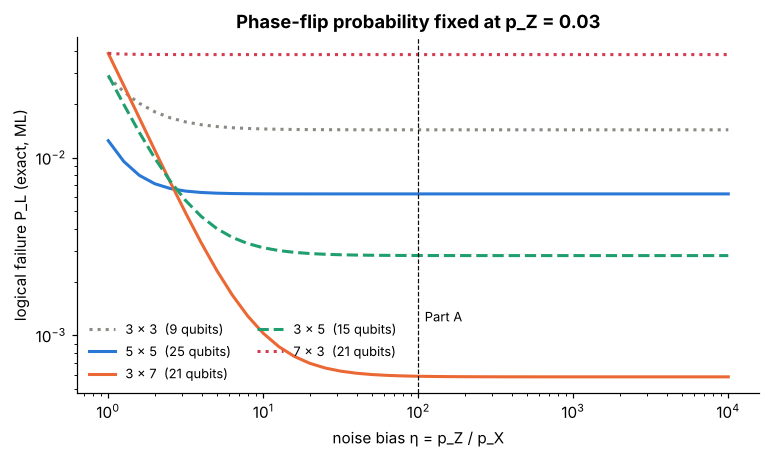

the 21-qubit 3 x 7 code beats the 25-qubit 5 x 5 code once the bias exceeds about 3


With no bias the square `5 × 5` code is best, and the stretched `3 × 7` code, with only 3 qubits of protection against
bit flips, is worse. As the bias grows, bit flips stop mattering, and spending qubits on the phase-flip direction pays:
the stretched code then fails about ten times less often than the square one while using fewer qubits. Stretching the
wrong way (`7 × 3`, red) is always a bad idea here. The crossover sits at a bias of only about 3. **The best code depends on the noise.**

## Part B2: where the bias comes from, a cat qubit

The resonator is described by its photon-lowering operator $a$. Two processes act on it:

* **two-photon dissipation**, rate $\kappa_2$, with jump operator $L_2 = \sqrt{\kappa_2}\,(a^2 - \alpha^2)$. It removes
  photons in pairs and pushes the field onto $\pm\alpha$, and it cannot tell the two apart. Both $|{+\alpha}\rangle$ and
  $|{-\alpha}\rangle$ are stable.
* **single-photon loss**, rate $\kappa_1$, jump operator $L_1 = \sqrt{\kappa_1}\,a$: the unavoidable imperfection.

The state evolves by the **Lindblad master equation**
$\dot\rho = \mathcal{L}\rho = \sum_j \big(L_j\rho L_j^\dagger - \tfrac12\{L_j^\dagger L_j, \rho\}\big)$.
Its slowest decay rates (eigenvalues of $\mathcal{L}$) are exactly the logical error rates. The bit-flip rate is
the slowest one, describing population leaking between the two lobes. The phase-flip rate is the decay of the
coherence between the lobes. We use $\kappa_1/\kappa_2 = 10^{-2}$ and a Fock space large enough for the result to stop
changing.

spectra computed in 43 s (rates in units of κ2)
bit-flip rate falls by a factor e^2.28 = 9.7 per extra photon (n̄ ≥ 3)
phase-flip rate / (κ1 n̄): 0.997 to 1.014


,Fock states,bit-flip rate,phase-flip rate,change with +6 states,bias η
nbar,,,,,
1.000000,21,1.95e-04,0.0101,4e-10,5.20e+01
1.500000,23,4.08e-05,0.0150,6e-09,3.67e+02
2.000000,25,8.02e-06,0.0199,8e-08,2.49e+03
2.500000,27,1.59e-06,0.0249,1e-07,1.57e+04
3.000000,28,3.45e-07,0.0299,3e-07,8.69e+04
3.500000,30,8.56e-08,0.0349,5e-06,4.08e+05
4.000000,32,2.47e-08,0.0399,2e-05,1.62e+06
4.500000,33,7.93e-09,0.0449,7e-06,5.67e+06
5.000000,34,2.72e-09,0.0499,4e-05,1.83e+07


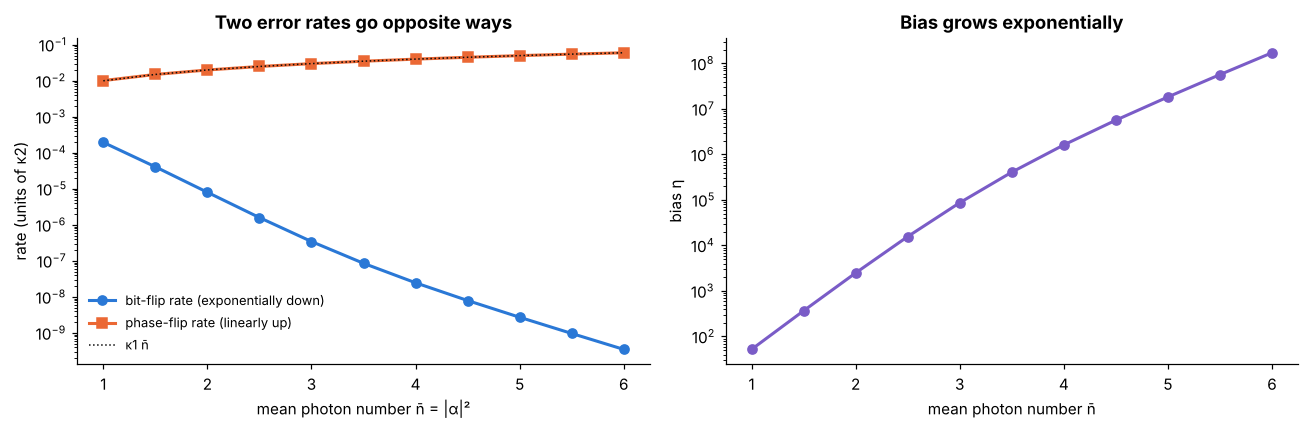

Every extra photon makes bit flips several times rarer, while phase flips grow only in proportion to the photon number,
at almost exactly $\kappa_1\bar n$. A few photons are enough for a bias of thousands. The second column of the table
shows how little the rates change with a bigger Fock space. (Rates below about $10^{-10}$ approach the limits of
double-precision eigenvalues, which is why the scan stops at $\bar n = 6$.)

## Animation: watching a cat qubit in phase space

The **Wigner function** draws a quantum state of light as a landscape over position and momentum. A coherent state is a
single blob. A cat state is two blobs **plus interference fringes** between them, which carry the quantum
superposition, the phase information. Here we use $\bar n = 4$ and a large photon loss, $\kappa_1 = 0.05\,\kappa_2$, so
the effect is visible within the movie.

* **left:** start in the cat state $|{+\alpha}\rangle + |{-\alpha}\rangle$. Single-photon losses scramble the parity and
  the fringes fade: **phase flips**.
* **right:** start in $|{+\alpha}\rangle$ (logical 0). Two-photon dissipation holds it in place: **no bit flips**.

checks: ∫W = 0.9994, W(0) of the even cat = 0.6366 (2/π = 0.6366)


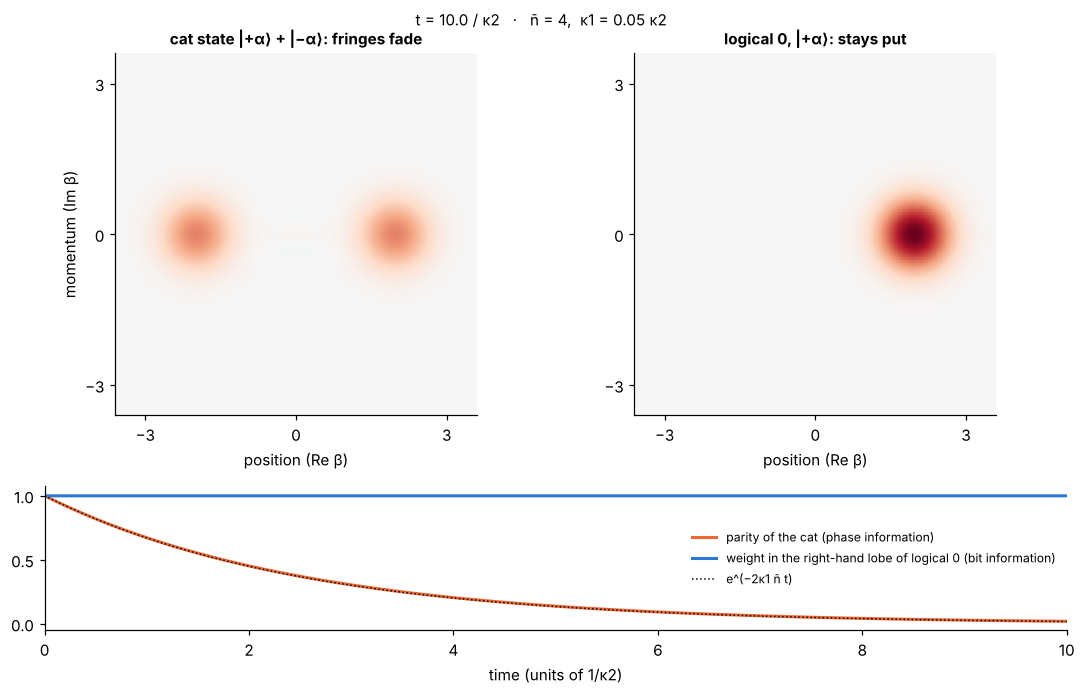

saved qe019_cat_qubit.gif (33 s): cat parity 0.020 (prediction 0.018), logical 0 still 0.9994 in its lobe


**The animation** (embedded, so it plays on GitHub without running anything):

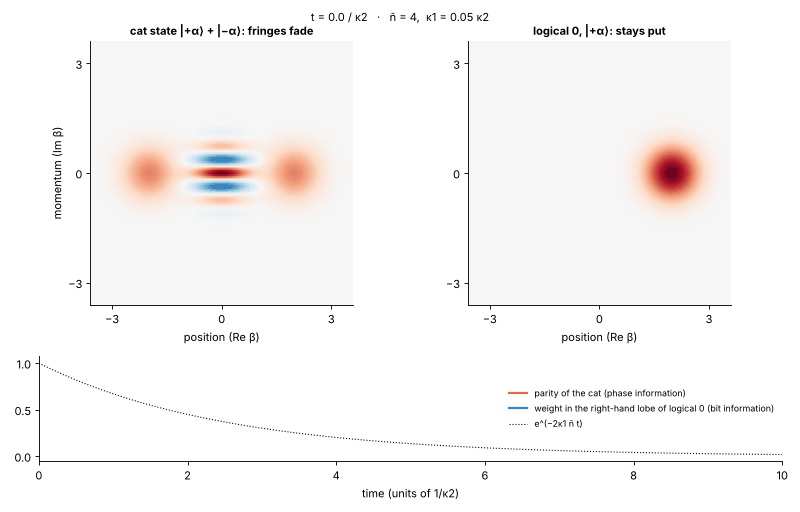

## Part B3: a gate that keeps the bias

Error correction needs two-qubit gates, and a gate can **convert** a harmless kind of error into a harmful one. Take the
CNOT. On ordinary qubits it is a continuous rotation: $U(s) = \exp\!\big[-i s\,\tfrac{\pi}{4}(1 - Z_c)(1 - X_t)\big]$
for $s$ from 0 to 1. If the target suffers a phase flip $Z_t$ partway through, at time $s$, that error is dragged
through the rest of the gate and comes out as $E = U(1-s)\,Z_t\,U(1-s)^\dagger$. We split $E$ into Pauli errors and ask
what fraction contains an X or Y, a **bit flip created from a phase flip**.

On cat qubits, the CNOT can be done by **rotating the target's phase space by 180°** if the control is in $|1\rangle$:
$U(s) = |0\rangle\langle0| \otimes 1 + |1\rangle\langle1| \otimes e^{i\pi s\,a^\dagger a}$. The rotation swaps
$|{+\alpha}\rangle$ and $|{-\alpha}\rangle$, which is a bit flip, as a CNOT needs. The dominant error is a photon
loss $a$ on the target. Since $a\,e^{i\theta a^\dagger a} = e^{i\theta}\,e^{i\theta a^\dagger a}\,a$, the loss only
picks up a phase, so it stays a phase-type error at every moment of the gate.

cat CNOT acts on the logical states as a CNOT: True


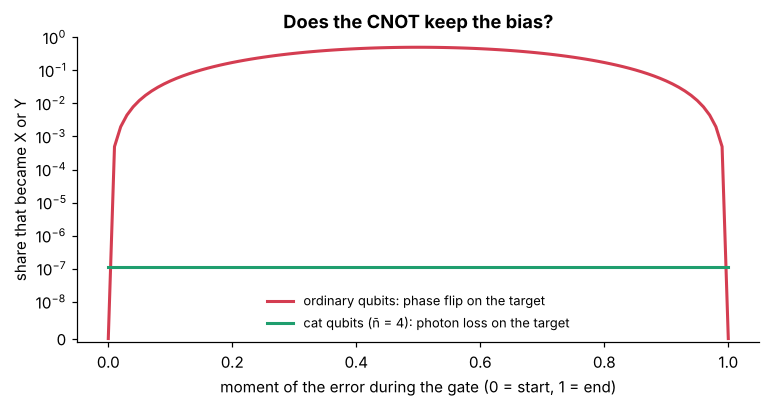

ordinary qubits: up to 0.50 of the error becomes a bit flip (error halfway through the gate)
cat qubits: at most 1.1e-07, compare e^(-4 n̄) = 1.1e-07


On ordinary qubits a phase flip halfway through the gate comes out **half bit flip**. No continuous two-level gate can
avoid this, because rotating $X_t$ through intermediate angles always mixes in other Pauli components. Biased noise
would be wasted the moment the qubits interact. The cat-qubit gate rotates through a continuum of states outside the
two-level picture, and a photon loss stays a phase-type error. The tiny leftover ($\sim10^{-7}$ at $\bar n = 4$) comes
from the small overlap of $|{+\alpha}\rangle$ and $|{-\alpha}\rangle$. This **bias-preserving CNOT** is what makes the
biased-noise codes above usable for computation, not only for storage.

## Part B4: the extreme case, a repetition code of cat qubits

If bit flips are rare enough, you can ignore them in the code and correct only phase flips with a **repetition code**:
$d$ cat qubits, read by majority vote. Its failure probability per error-correction cycle is exactly

$$P_L = 1 - (1 - P_\text{maj})(1 - P_\text{odd}),\qquad
P_\text{maj} = \sum_{k > d/2} \binom{d}{k} p_Z^k (1-p_Z)^{d-k},\qquad
P_\text{odd} = \tfrac12\big[1 - (1 - 2p_X)^d\big],$$

where $P_\text{odd}$ is the chance of an odd number of uncorrected bit flips. The photon number now becomes a design
knob: more photons suppress $p_X$ exponentially but raise $p_Z$. We take the rates from Part B2 for one cycle of
duration $1/\kappa_2$, using the exponential fit to extend the bit-flip rate beyond $\bar n = 6$.

*Simplification:* this counts only errors on idle cat qubits. Real cycles include CNOTs and measurements, which add
errors and give the repetition code a threshold of a few percent instead of 50%.

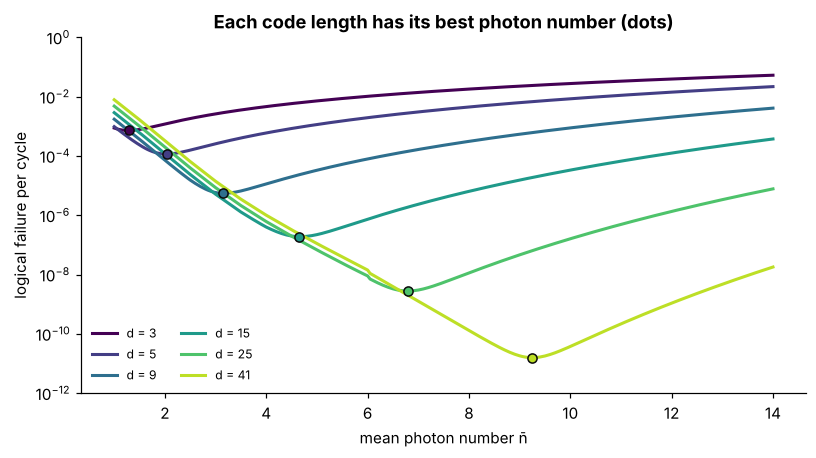

,best n̄,lowest P_L,p_Z there,bias there
repetition length d,,,,
3,1.30,7.3e-04,0.013,1.7e+02
5,2.05,1.2e-04,0.020,3.0e+03
9,3.15,5.6e-06,0.032,1.4e+05
15,4.65,1.9e-07,0.047,8.1e+06
25,6.80,2.8e-09,0.068,1.4e+09
41,9.25,1.6e-11,0.092,5.0e+11


For each code length there is a best photon number. Too few photons and the uncorrected bit flips dominate; too many
and the phase flips overwhelm the majority vote. Longer codes can handle more phase flips, so they want more photons,
and the achievable failure rate keeps falling. This **co-design** (choosing the physical knob and the code together)
is the central idea of biased-noise architectures.

## Part B5: many logical qubits in one block

The surface code stores **one** logical qubit per block. The **hypergraph product** builds quantum codes from two
classical codes with check tables $H_1$, $H_2$:

$$H_X = \big[\,H_1 \otimes 1 \;\big|\; 1 \otimes H_2^{\mathsf T}\big],\qquad
H_Z = \big[\,1 \otimes H_2 \;\big|\; H_1^{\mathsf T} \otimes 1\big].$$

(The surface code is the hypergraph product of two repetition codes.) Take $H_1$ = a length-$d$ **repetition code**,
giving the long phase-flip distance, and $H_2$ = a **Hamming code**, a classical code with high rate. The product is an
asymmetric code storing $k$ logical qubits with $d_Z = d$ and $d_X = 3$. The Hamming code is *cyclic*: its codewords
are shifts of one another. **Lifted-product codes** push this idea further: they build large codes out of blocks of
cyclically shifted (circulant) matrices, keeping every check small while reaching rates the surface code cannot.

rep(5) × Hamming(7): n = 47, k = 4, d_Z = 5 (brute force), weight-3 X logical exists: True


d_X  qubits n  logical qubits k  qubits per logical  \
Hamming length d_Z                                                        
7              5      3        47                 4               11.75   
               7      3        67                 4               16.75   
               9      3        87                 4               21.75   
15             5      3        91                11                8.27   
               7      3       129                11               11.73   
               9      3       167                11               15.18   
31             5      3       175                26                6.73   
               7      3       247                26                9.50   
               9      3       319                26               12.27   

                    same k with 3 × d surface codes  saving  
Hamming length d_Z                                           
7              5                                 60    1.28  
               7                                 84    1.25  
               9                                108    1.24  
15             5                                165    1.81  
               7                                231    1.79  
               9                                297    1.78  
31             5                                390    2.23  
               7                                546    2.21  
               9                                702    2.20

The check passes: $[1,1,1,0,0,0,0]$ is a Hamming codeword (it satisfies all three checks), and placed along one row it
is an undetected bit-flip logical of weight 3. The general theory of hypergraph products (Tillich and Zémor) confirms
that $d_X = 3$ and $d_Z = d$ for all the codes in the table. With a 31-bit Hamming code, one block holds 26 logical
qubits, each as well protected against phase flips as a `3 × d` surface code, with fewer than half the qubits those
26 separate codes would need. The catch: logical gates inside such blocks are harder (that is where ideas such as homomorphic or transversal
gates come in), and Hamming checks get heavy as the code grows, which is what sparse lifted-product constructions fix.

## Conclusions

1. **Exact answer.** The 21-qubit `3 × 7` surface code at $p_Z = 3\%$, bias 100, fails with probability
   $P_L = 5.886783\times10^{-4}$ under ML decoding, so $A = 588678$. That is about ten times better than the
   25-qubit square `5 × 5` code.
2. **The best code depends on the noise.** Without bias, square is best. Above a bias of about 3, the stretched code wins.
3. **Cat qubits make the bias.** Two-photon dissipation suppresses bit flips by a factor of about 10 per photon,
   while phase flips rise only as $\kappa_1\bar n$.
4. **Gates must keep the bias.** On two-level qubits a CNOT turns up to half of a phase flip into a bit flip. The
   cat-qubit CNOT keeps it a phase flip to within $\sim10^{-7}$.
5. **Co-design pays.** The photon number and the code length must be chosen together, and high-rate product codes
   store many logical qubits in a block for a fraction of the qubits.

**Try it yourself:** replace the rotated surface code with the XZZX code, add measurement errors to the repetition
code (repeat the syndrome over several rounds), simulate a cat qubit with thermal noise or dephasing, or use the
enumeration machinery to compare $d_X \times d_Z$ shapes at other biases.

### Further reading

* M. Mirrahimi et al., *Dynamically protected cat-qubits: a new paradigm for universal quantum computation*,
  New J. Phys. 16, 045014 (2014).
* J. Guillaud, M. Mirrahimi, *Repetition cat qubits for fault-tolerant quantum computation*, Phys. Rev. X 9, 041053 (2019).
* S. Puri et al., *Bias-preserving gates with stabilized cat qubits*, Science Advances 6, eaay5901 (2020).
* D. K. Tuckett, S. D. Bartlett, S. T. Flammia, *Ultrahigh error threshold for surface codes with biased noise*,
  Phys. Rev. Lett. 120, 050505 (2018).
* J. P. Bonilla Ataides et al., *The XZZX surface code*, Nature Communications 12, 2172 (2021).
* J.-P. Tillich, G. Zémor, *Quantum LDPC codes with positive rate and minimum distance proportional to √n*,
  IEEE Trans. Inf. Theory 60, 1193 (2014).
* P. Panteleev, G. Kalachev, *Degenerate quantum LDPC codes with good finite length performance*, Quantum 5, 585 (2021).
* C. Berdou et al., *One hundred second bit-flip time in a two-photon dissipative oscillator*, PRX Quantum 4, 020350 (2023).